# AIRBNB — Báo cáo dữ liệu và thiết kế nghiên cứu propensity

**Phạm vi:** EDA trên raw, phân tích nhãn/độ trễ/cohort và đề xuất thiết kế. Chưa làm sạch, tạo feature, tạo tập chia hoặc huấn luyện mô hình.

Notebook có output lưu sẵn để đọc ngay. **Notebook phụ thuộc package scripts/ và CSV của dự án; một file notebook riêng không chạy độc lập.** Khi nộp cần kèm code và hướng dẫn lấy dữ liệu sau:

    Propensity/
      scripts/
        __init__.py
        build_descriptive_reports.py
        eda_diagnostics.py
        airbnb_deep_dive.py
      data/raw/AIRBNB/
        train_users_2.csv
        test_users.csv
        sessions.csv
        countries.csv
        age_gender_bkts.csv
      notebooks/AIRBNB/airbnb_descriptive_report.ipynb

CSV lấy từ cuộc thi Airbnb New User Bookings, không có trong Git. File sample_submission_NDF.csv là tùy chọn để kiểm kê, không dùng phân tích người dùng. Xem báo cáo Markdown được tạo tại reports/AIRBNB/README.md sau khi chạy.

Môi trường EDA đã kiểm tra: Python 3.14.2; pandas 2.3.3, numpy 2.4.1, scipy 1.17.1, matplotlib 3.10.8, nbformat 5.10.4 và IPython 9.9.0. Có thể cài các thư viện EDA trong môi trường riêng bằng:

    python -m pip install pandas==2.3.3 numpy==2.4.1 scipy==1.17.1 matplotlib==3.10.8 nbformat==5.10.4 ipython==9.9.0 tzdata

Dùng Jupyter với kernel của môi trường đó, Restart Kernel và Run All từ đầu; hoặc chạy python scripts/build_descriptive_reports.py --dataset AIRBNB ở thư mục gốc. Lần chạy tạo lại báo cáo, hình và metadata từ CSV; ngày thực thi được lưu trong metadata notebook. Seed hiển thị hình =42. **Ngày tải raw không được lưu**, đã được người cung cấp xác nhận; dùng SHA-256 để đối chiếu snapshot.


In [1]:
from pathlib import Path
import importlib
import sys
from datetime import datetime
from zoneinfo import ZoneInfo

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents)
                     if (p / 'scripts' / 'build_descriptive_reports.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Notebook cần package scripts/ của dự án; xem cấu trúc thư mục trong ô mở đầu.')
required = [PROJECT_ROOT / 'scripts' / name for name in
            ['__init__.py', 'build_descriptive_reports.py', 'eda_diagnostics.py', 'airbnb_deep_dive.py']]
required += [PROJECT_ROOT / 'data' / 'raw' / 'AIRBNB' / name for name in
             ['train_users_2.csv', 'test_users.csv', 'sessions.csv', 'countries.csv', 'age_gender_bkts.csv']]
missing = [str(p.relative_to(PROJECT_ROOT)) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError('Thiếu file để chạy lại Airbnb: ' + ', '.join(missing))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts import build_descriptive_reports as eda
importlib.reload(eda)
report = eda.build_report('AIRBNB', PROJECT_ROOT)
print('Ngày tính lại (Asia/Ho_Chi_Minh):', datetime.now(ZoneInfo('Asia/Ho_Chi_Minh')).isoformat())
print('Đã tính EDA từ CSV raw; số chính:', report.facts)
print('Không tạo tập feature, tập chia hoặc mô hình. Ngày tải: không được lưu; snapshot theo SHA-256.')


Ngày tính lại (Asia/Ho_Chi_Minh): 2026-11-02T01:47:12.683959+07:00
Đã tính EDA từ CSV raw; số chính: {'rows': 213451, 'columns': 16, 'positive': 88908, 'rate': 0.4165265095970504, 'sessions': 10567737, 'session_users': 135483, 'train_session_users': 73815, 'test_session_users': 61668, 'test_rows': 62096, 'sessions_missing_ids': 34496, 'figure_seed': 42, 'rules_checked_on': '2026-11-01', 'download_date_status': 'not_recorded_confirmed_by_provider_2026-11-02', 'dataset_version_status': 'unknown_kaggle_version_local_snapshot_identified', 'local_snapshot_sha256': '45e506f76002c40e6710fe27864a365bd0476ceae98e4e2803d7bd239c01114c', 'valid_booking_lags': 88879, 'negative_booking_lags': 29, 'booking_coverage_30_pct': 75.32713014322844, 'booking_coverage_60_pct': 80.25855376410625, 'booking_coverage_90_pct': 83.2896409725582, 'max_observed_booking_lag_days': 365, 'train_2014_users': 76466, 'train_2014_session_users': 73815, 'train_2014_session_coverage_pct': 96.5330996782884, 'session_action_au

## Tóm tắt điều hành

In [2]:
eda.show_section(report, 'executive')

1. **Bài toán đã chọn:** xác suất user mới có booking đầu được ghi nhận, t0 thiết kế ngay sau tạo account; 213,451 user train và 62,096 test. Horizon nguồn chưa được xác nhận; xem phần 1.

2. **Nhãn và độ trễ:** 88,908 user có booking (41.65%); trong 88,879 độ trễ không âm, 30/60/90 ngày bao phủ 75.33%/80.26%/83.29%. Xem bảng độ trễ phần 5.

3. **Ngoại lệ nhãn:** 29 booking trước ngày account; max độ trễ ở mọi năm là 365 ngày. Đây là căn cứ điều tra cơ chế nhãn, chưa chứng minh NDF đã được theo dõi đủ một năm.

4. **Leakage đã chứng minh:** presence date_first_booking khớp 100% nhãn; giữ bảng chéo tại phần 3. Cột này và cờ thiếu không là đầu vào dự đoán.

5. **Liên hệ có định lượng:** gender có V=0.207 toàn kỳ và 0.251 trong 2014; signup_app tương ứng 0.109/0.156. Bảng đủ biến và phân tầng ở phần 5, chưa là chất lượng mô hình.

6. **So sessions cùng điều kiện:** train 2014 96.53% so với test 2014 99.31%, chênh 2.78 điểm phần trăm. 76,466 user train nằm trong phạm vi cohort có log; xem phần sessions.

7. **Có log không đồng nghĩa nhãn giống nhau:** trong 2014, booking rate có log 38.98%, không log 17.54%. Cần đọc cùng n/Wilson; không dùng presence log làm tín hiệu tại signup khi chưa chứng minh t0.

8. **Missing và tuổi:** age thiếu 41.22%; trong 2014, cờ thiếu tuổi có V=0.374, còn rank-biserial của tuổi 16–100 là -0.005. Hai thước đo khác nhau; kết quả nhấn mạnh cần kiểm tra tính đầy đủ hồ sơ và snapshot tại t0. Giữ riêng NA, unknown và untracked.

9. **Thiết kế tiếp theo đã cụ thể hóa:** baseline hằng/Logistic L2, CatBoost và calibration; rolling theo signup, calibration tháng 4/2014, đánh giá cuối tháng 5–6/2014. Đây là protocol đề xuất, chưa chia tập hay train.

## 1. Bài toán và lý do chọn dữ liệu

In [3]:
eda.show_section(report, 'problem')

**Bối cảnh nghiệp vụ:** ưu tiên hỗ trợ onboarding/cá nhân hóa cho người dùng mới dựa trên khả năng phát sinh booking đầu. Điểm propensity mô tả xu hướng hành vi; chưa phải tác động tăng thêm do một chiến dịch.

**Phát biểu bài toán nghiên cứu đã chọn:** với một user mới, sử dụng thông tin đăng ký sẵn có tại t0 để ước lượng xác suất có booking đầu được ghi nhận trong nhãn nguồn. Đầu ra là một xác suất [0,1] cho mỗi user, phục vụ sắp ưu tiên; bài toán điểm đến 12 lớp được giữ làm bối cảnh EDA.

**t0 thiết kế:** ngay sau khi hoàn tất tạo tài khoản. date_account_created chỉ chính xác tới ngày nên không xác minh được thứ tự trong ngày. Nhãn nghiên cứu y=1 khi country_destination khác NDF; y=0 khi NDF, không diễn giải thành “không bao giờ book”. Các giá trị hồ sơ phải được xác minh là snapshot tại signup. 29 booking có ngày trước account chưa thỏa logic first-booking tương lai tại t0; đề xuất cách ly để xác minh ở giai đoạn sau, chưa xóa.

**Horizon:** phạm vi hiện tại là kết quả được ghi nhận theo cơ chế nhãn nguồn, không tự đổi thành nhãn 90 ngày. Horizon nghiệp vụ đề xuất là 90 ngày vì bao phủ 83.29% booking quan sát hợp lệ; muốn triển khai cần xác nhận ngày kết thúc theo dõi và nhãn âm. Nếu không xác minh được, chỉ được kết luận về bài toán nghiên cứu theo nhãn nguồn.

**Lý do chọn Airbnb so với hai bộ còn lại**

,dataset,unit,evidence,fit,decision
0,AIRBNB,User mới,"213,451 user; 41.65% có booking",Đúng đối tượng chấm propensity khách hàng; có ID,"Chọn cho nghiên cứu, còn điều kiện nhãn/t0"
1,HOTEL,Booking đã được tạo,Nhãn hủy/no-show; không quan sát đầy đủ người ...,Hợp cancellation propensity,Không trả lời trực tiếp ai sẽ tạo booking đầu
2,EXPEDIA,Cặp search–hotel,Tương tác trong danh sách; thiếu user ID và se...,Hợp ranking/propensity trong search,Không ưu tiên cho propensity onboarding theo user


## 2. Tổng quan bộ dữ liệu

In [4]:
eda.show_section(report, 'overview')

### Nguồn gốc và phạm vi thu thập

Nguồn công bố: [trang dữ liệu/nghiên cứu gốc](https://www.kaggle.com/c/airbnb-recruiting-new-user-bookings/data). [Giấy phép/điều khoản và trang phân phối](https://www.kaggle.com/competitions/airbnb-recruiting-new-user-bookings/rules). Thông tin nào chưa được lưu hoặc chưa xác minh được được ghi rõ, không điền bằng giả định.

**Thông tin nguồn và phiên bản**

,item,description
0,Tên / nơi công bố,Airbnb / Kaggle — Airbnb New User Bookings
1,Năm công bố,"Cuộc thi công bố 2015, kết thúc 2016"
2,Mục đích thu thập/công bố,Dự đoán quốc gia của booking đầu cho người dùn...
3,Cách thu thập / quần thể,"Hồ sơ đăng ký, web/app logs và các bảng tổng h..."
4,Thời gian bao phủ quan sát được,Account train 2010-01-01–2014-06-30; test 2014...
5,Ngày tải raw,Không được lưu; người cung cấp xác nhận 2026-1...
6,Quy mô bảng train/chính,"213,451 dòng × 16 cột thô"
7,Dung lượng mọi CSV của bộ hiện có,"664,207,331 byte = 633.44 MiB; gồm cả bảng phụ..."
8,Phiên bản local,"Nhận diện bằng tên file, bytes, số dòng và SHA..."
9,Giấy phép / điều khoản,"Competition Rules, không phải giấy phép mở CC0..."


### Bối cảnh, đơn vị quan sát và phạm vi nhãn

Train gồm **213,451 người dùng, 16 cột**, test gồm **62,096 người dùng, 15 cột**. Nhãn gốc là `country_destination` với 12 giá trị, gồm `NDF` và 11 điểm đến/nhóm điểm đến còn lại. Đối với propensity nhị phân, báo cáo chỉ thống kê hành vi **có booking được ghi nhận** khi nhãn khác NDF; không tạo tập nhãn huấn luyện mới.

Mục tiêu gốc là dự đoán điểm đến booking đầu, không trực tiếp cung cấp nhãn booking trong 30/60/90 ngày. `NDF` nghĩa không có booking theo nhãn của bộ dữ liệu; không khẳng định người dùng sẽ không bao giờ book. Phân tích độ trễ và độ nhạy horizon ở phần 5 phân biệt nhãn nguồn với nhãn triển khai theo thời hạn.

[Mô tả cuộc thi Airbnb New User Bookings](https://www.kaggle.com/c/airbnb-recruiting-new-user-bookings/data) nêu người dùng trong tập đến từ Mỹ. Vì vậy tính đại diện về địa lý, thời kỳ và sản phẩm có giới hạn. Test công khai không có nhãn để tính chất lượng dự đoán hoặc so sánh booking rate với train.

## 3. Chất lượng dữ liệu

### Chất lượng users, sentinel và rò rỉ nhãn

**Rò rỉ đã kiểm chứng:** presence của `date_first_booking` khớp nhãn có booking ở **100.00%** người dùng train. Không dùng ngày này, hoặc cờ thiếu ngày này, làm đầu vào dự đoán booking đầu. Đây là thiếu theo cấu trúc kết quả, không phải missing cần impute.

Tuổi ngoài [16,100] được gắn cờ cho EDA; đây là **dải tham chiếu**, không phải chính sách hợp lệ đã xác nhận. Giá trị dạng 19xx/20xx có thể là năm sinh nhưng CSV không chứng minh nguyên nhân của từng dòng; không đổi tuổi, xóa người dùng hay thay giá trị. Gender/browser có sentinel cần thống kê riêng với NA.

Ngày hoạt động đầu trước ngày tạo tài khoản được nguồn gốc cho phép vì có thể tìm kiếm trước khi đăng ký. Có **29** dòng ngày booking trước ngày account; đây là câu hỏi về định nghĩa mốc thời gian cần xác minh, không tự động kết luận lỗi rồi loại bỏ.

**Kiểm tra định danh và logic thời gian**

,check,n
0,ID train bị lặp (beyond first),0
1,ID test bị lặp (beyond first),0
2,ID xuất hiện ở cả train và test,0
3,date_first_booking.notna không khớp nhãn có bo...,0
4,date_first_booking có giá trị trong test,0
5,"Tuổi có giá trị nhưng ngoài [16,100] (quy ước ...",2410
6,Booking đầu trước ngày tạo tài khoản,29
7,Hoạt động đầu trước ngày tạo tài khoản,178
8,Ngày account không parse được,0
9,Timestamp hoạt động đầu không parse được,0


**NA và giá trị đặc biệt là các khái niệm khác nhau**

,column,null_n,minus_unknown_n,untracked_n
0,gender,0,95688,0
1,first_browser,0,27266,0
2,first_affiliate_tracked,6065,0,109232


... (2 outputs left out)

### Missing có quy luật hay không?

Heatmap chọn tối đa 12 cột có NA. Chọn dòng để hiển thị với seed=42 và sắp theo pattern; bảng tỷ lệ theo nhóm dùng quần thể phân tích công bố, không chỉ các dòng hiển thị.

**Missing (%) theo account year; toàn bộ users train AIRBNB**

,account year,date_first_booking,age,first_affiliate_tracked
0,2010,42.5036,38.8092,28.1564
1,2011,45.3673,34.7346,20.3227
2,2012,55.0226,34.8183,3.3120
3,2013,59.1562,42.1287,0.9462
4,2014,61.7621,44.6316,1.0397


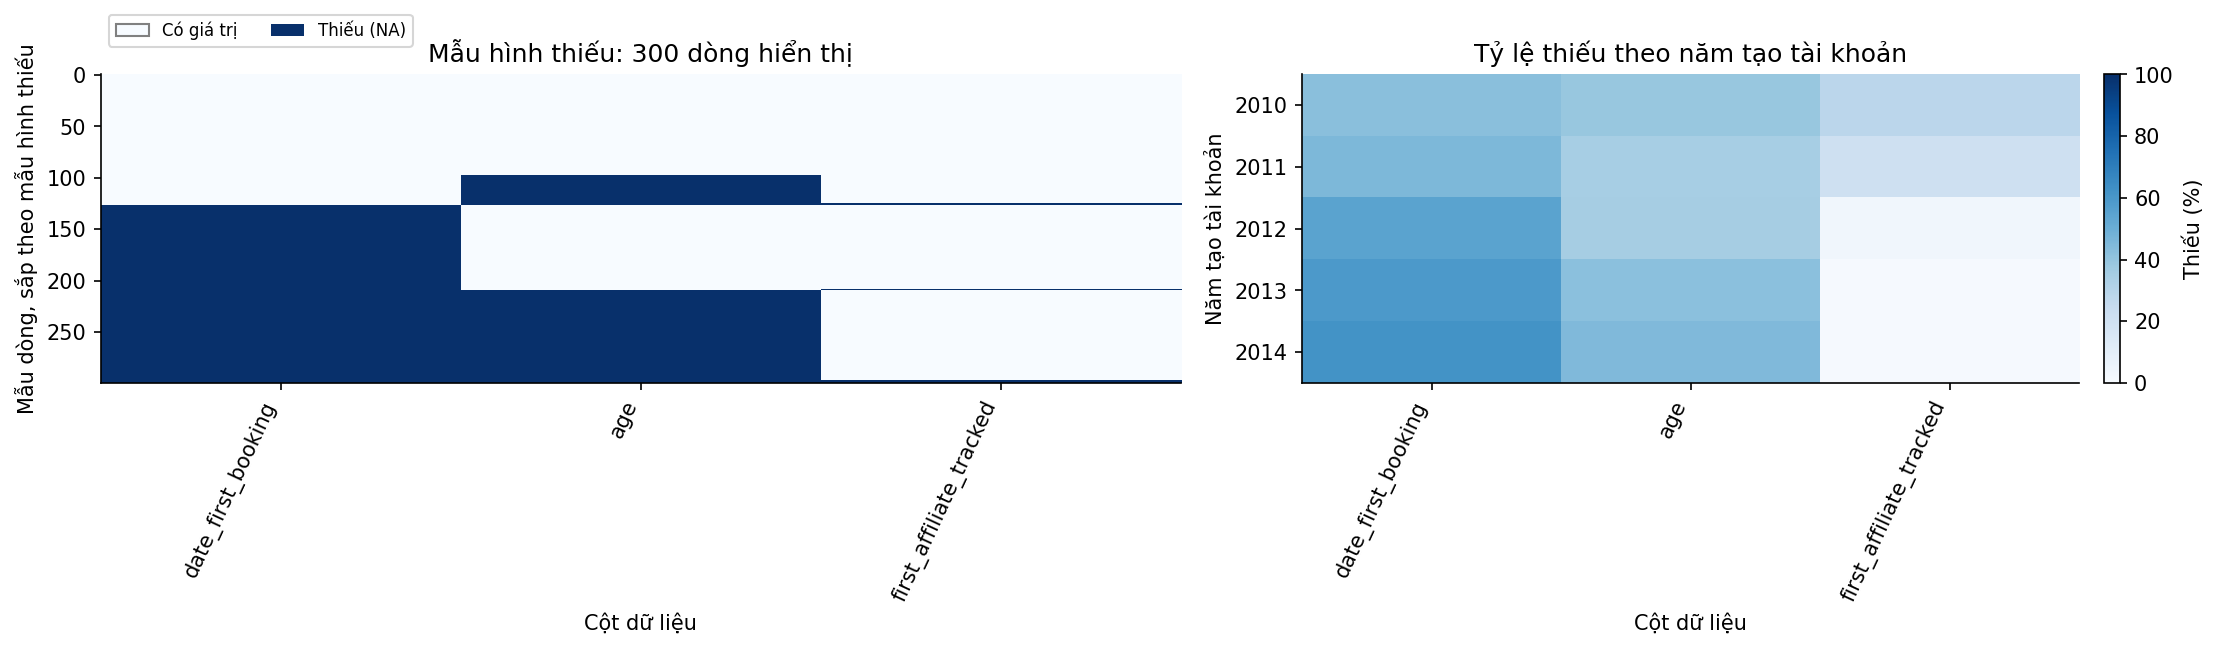

Nhận xét: date_first_booking thiếu 58.35% trong toàn bộ users train AIRBNB; chênh lệch missing lớn nhất giữa các nhóm account year là 27.21 điểm phần trăm ở first_affiliate_tracked. Ô xanh là NA. Mẫu dòng hiển thị dùng seed=42; việc sắp theo pattern chỉ để nhìn cụm thiếu, không phải thứ tự thời gian. Các khác biệt này không đủ kết luận cơ chế MCAR/MAR/MNAR.

### Ngoại lai: lượng hóa và phân biệt quy tắc với kết luận lỗi

Quy tắc 1,5×IQR chỉ gắn cờ để kiểm tra, không tự chứng minh lỗi. Mẫu số là số giá trị không thiếu của từng cột; bảng giữ rõ quần thể và trường hợp IQR=0.

**Hàng rào IQR trên dữ liệu công bố**

,column,population,nonnull_n,q1,q3,iqr,lower_fence,upper_fence,flagged_n,flagged_pct_nonnull,iqr_zero
0,age,toàn bộ users train AIRBNB,125461,28.0000,43.0000,15.0000,5.5000,65.5000,5594,4.4588,False


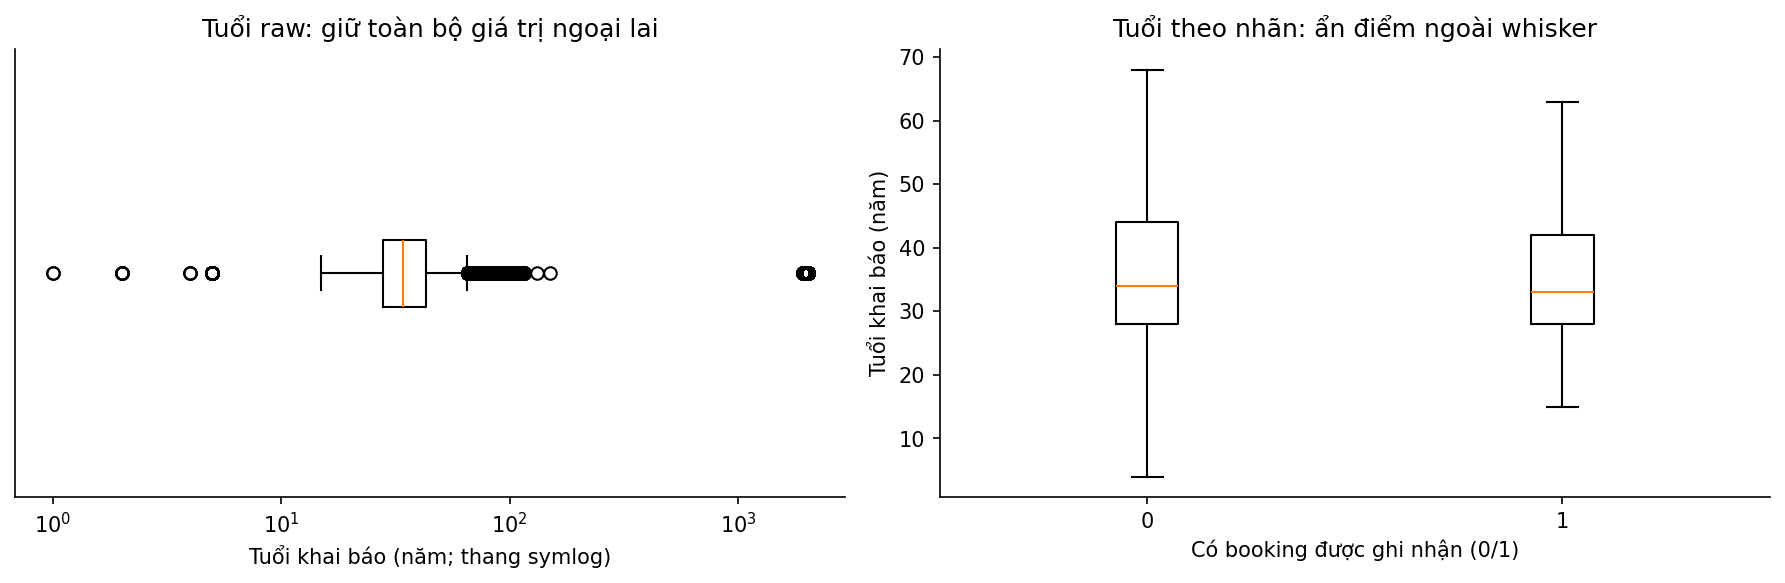

Nhận xét: theo hàng rào Q1−1,5×IQR và Q3+1,5×IQR, age có 5,594/125,461 giá trị bị gắn cờ (4.46%) trong toàn bộ users train AIRBNB; đây là bất thường thống kê, chưa phải lỗi nhập liệu. Median age theo nhãn: 0=34.00, 1=33.00. Boxplot bên phải ẩn các điểm ngoài whisker để đọc vùng giữa, không xóa chúng khỏi bảng hay raw. Đơn vị xem từ điển; IQR=0 ở biến rời rạc có thể gắn cờ nhiều giá trị thật. Trục x boxplot raw dùng symlog; hàng rào IQR vẫn tính trên giá trị raw, không phải log.

In [5]:
eda.show_section(report, 'quality_main')

## 4. Phân tích đơn biến

### Nhãn, tuổi và phân phối kênh/thiết bị

Có booking được ghi nhận: **88,908/213,451 (41.65%)**. Nhóm NDF chiếm **58.35%**. Bảng điểm đến trình bày hai mẫu số riêng: toàn bộ người dùng và chỉ người có booking; không nhầm tỷ trọng US trong toàn bộ users với tỷ trọng US trong nhóm đã book.

Độ tuổi được trình bày cả raw và cửa sổ [16,100] để thấy tác động của giá trị cực đoan. Top category có mẫu số là toàn bộ users, kể cả NA. `signup_flow` là mã phân loại; không báo cáo mean của mã như một đặc điểm khách hàng.

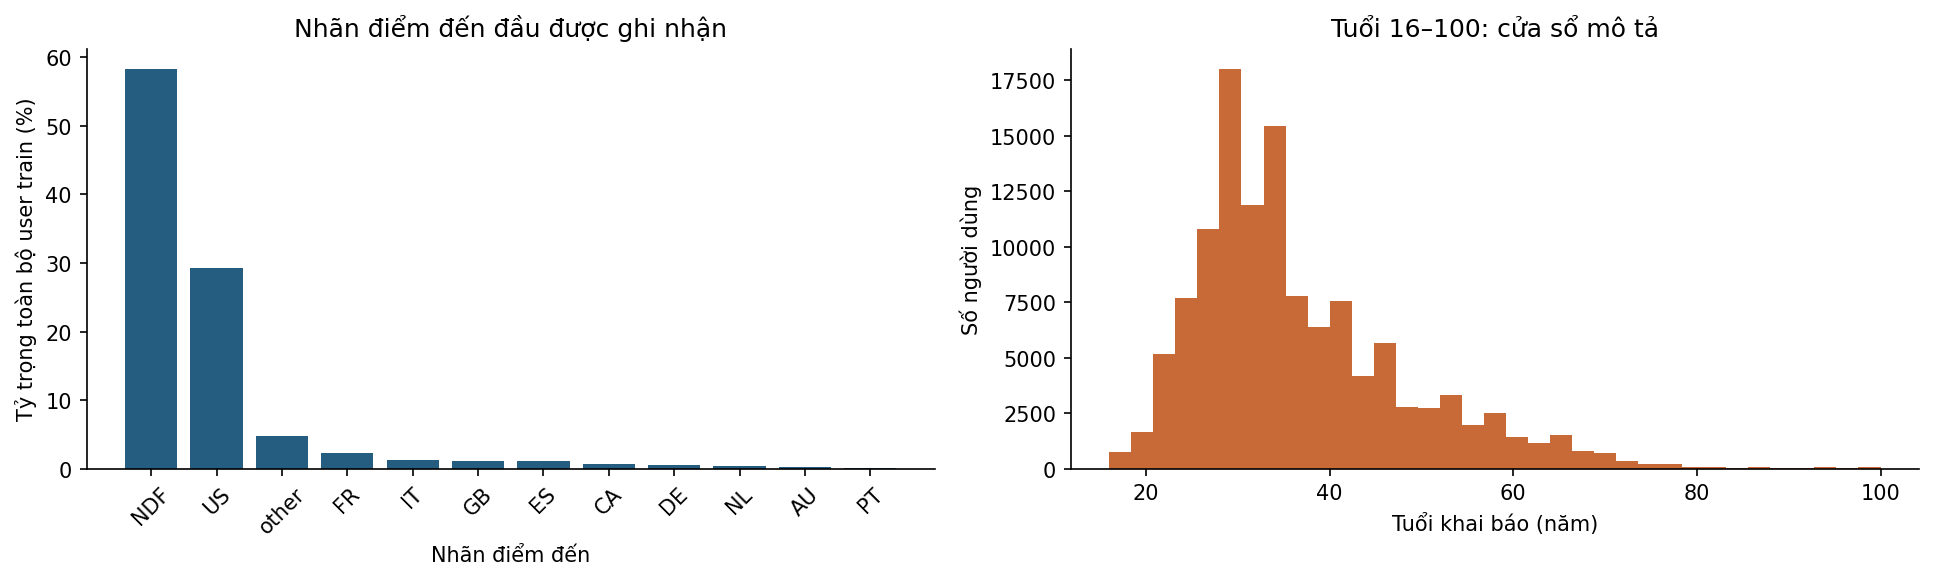

Nhận xét: NDF chiếm 58.35% toàn users; age thiếu 41.22% và có 2,410 giá trị ngoài dải tham chiếu 16–100. Histogram chỉ vẽ tuổi 16–100, không thay đổi raw hoặc khẳng định mọi tuổi ngoài dải đều sai.

### Biến phân loại và nhãn

Biểu đồ hiển thị top 8 nhóm theo số lượng; bảng kiểm kê giữ cả các nhóm nhỏ. Nhóm hiếm được báo với ngưỡng mô tả n<100, chưa gộp category.

**Tần suất đầy đủ của signup_app**

,signup_app,n,positive
0,Web,182717,80021
1,iOS,19019,5511
2,Moweb,6261,2143
3,Android,5454,1233


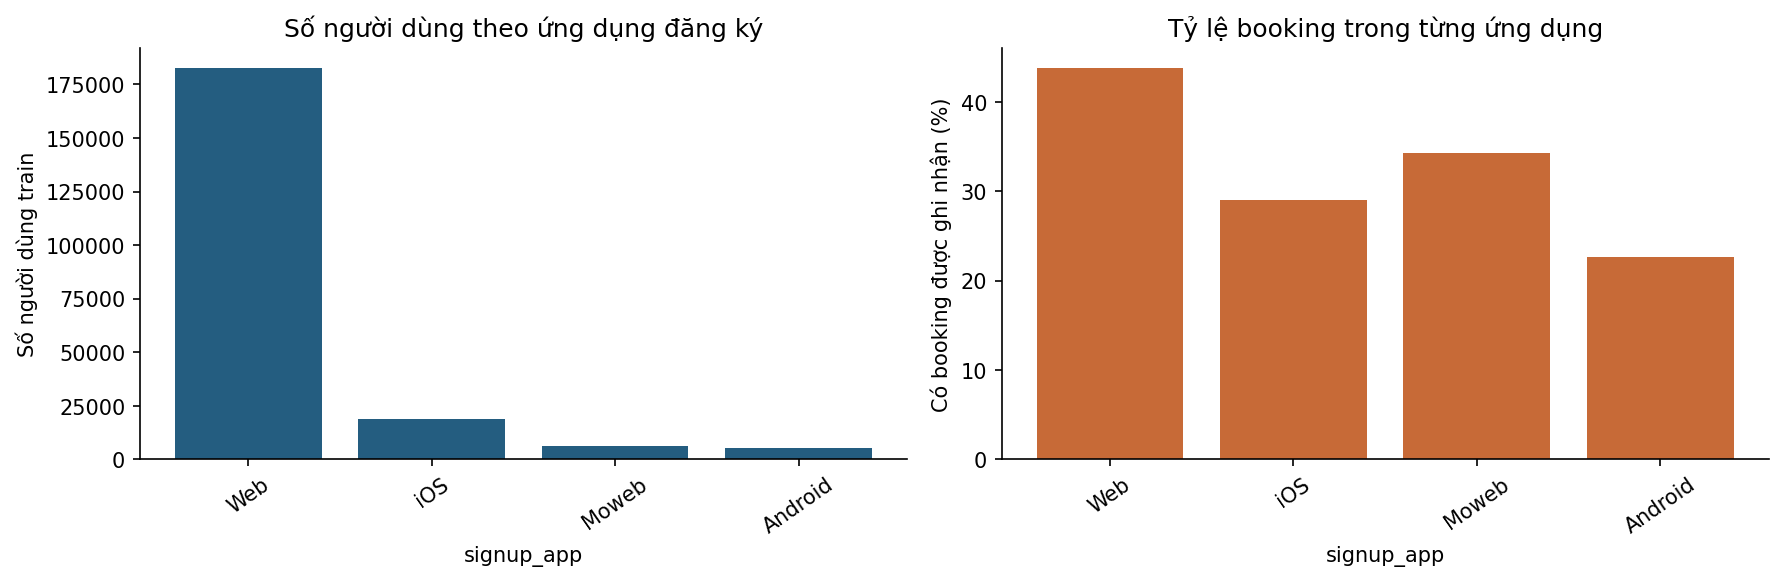

Nhận xét: signup_app có 4 nhóm (không có NA); 0 nhóm dưới 100 quan sát. Nhóm lớn nhất Web có 182,717 quan sát, tỷ lệ nhãn 1 là 43.80%. Hai trục trả lời số lượng nhóm và tỷ lệ bên trong nhóm, không dùng lẫn mẫu số; phân tầng cohort được trình bày tại phần đa biến.

In [6]:
eda.show_section(report, 'univariate')

## 5. Nhãn, liên hệ đa biến, cohort và sessions

### Độ trễ booking và giới hạn định nghĩa nhãn

Độ trễ = date_first_booking − date_account_created, tính bằng ngày lịch; ngày booking chỉ dùng để kiểm tra nhãn. Có 88,879 độ trễ không âm và 29 độ trễ âm. Không diễn giải độ trễ âm là booking tương lai và không sửa chúng trong EDA.

**Cửa sổ 90 ngày bao phủ 83.29% booking quan sát có độ trễ hợp lệ**, còn khoảng 16.71% nằm sau 90 ngày. Các tỷ lệ dưới đây không phải xác suất booking 30/60/90 ngày của toàn bộ user.

Ngày booking lớn nhất là 2015-06-29. Độ trễ lớn nhất ở cả năm cohort là 365 ngày. Điều này phù hợp với giả thuyết nhãn có giới hạn khoảng một năm theo từng user, nhưng chưa chứng minh cơ chế đóng nhãn hoặc thời gian theo dõi của NDF. **Không thể kết luận NDF ở cohort mới chỉ là chưa kịp booking, cũng chưa thể bác bỏ khả năng đó.**

Nếu giả định mọi user đều được theo dõi tới ngày booking lớn nhất, toàn bộ train có khoảng cách lịch đủ 30/60/90 ngày. Đây là phân tích độ nhạy theo một giả định chưa kiểm chứng, không phải bằng chứng xác nhận NDF đã trưởng thành. Bài toán chính dùng nhãn nguồn; 90 ngày là horizon triển khai cần dữ liệu bổ sung để xác nhận nhãn âm.

**Phân phối độ trễ: mẫu số và ngoại lệ**

,booked_users,valid_nonnegative_lags,negative_lags,missing_or_unparsed_booked_dates,median_days,p75_days,p90_days,p95_days,max_days
0,88908,88879,29,0,3.0000,29.0000,189.0000,278.0000,365.0000


**Mức bao phủ các horizon trên booking đã quan sát**

,horizon_days,bookings_within_h,denominator_valid_bookings,pct_valid_bookings,pct_all_observed_bookings
0,7,55366,88879,62.2937,62.2734
1,30,66950,88879,75.3271,75.3026
2,60,71333,88879,80.2586,80.2324
3,90,74027,88879,83.2896,83.2625
4,180,79524,88879,89.4745,89.4453
5,365,88879,88879,100.0000,99.9674


**Độ trễ theo năm tạo tài khoản**

,account_year,users,valid_bookings,negative_lags,within_30_pct,within_60_pct,within_90_pct,max_lag_days,latest_booking
0,2010,2788,1597,6,86.6625,90.3569,91.9224,365.0000,2011-11-30
1,2011,11775,6422,11,80.5824,84.2884,86.4217,365.0000,2012-12-09
2,2012,39462,17738,11,76.5024,81.4241,84.2541,365.0000,2013-12-31
3,2013,82960,33883,1,74.4503,79.2492,82.3156,365.0000,2014-12-30
4,2014,76466,29239,0,73.8568,79.2845,82.6738,365.0000,2015-06-29


**Giả định chung ngày đóng nhãn: chỉ là độ nhạy**

,assumed_common_cutoff,horizon_days,users_with_calendar_gap_ge_h,pct_users,status
0,2015-06-29,30,213451,100.0000,Chỉ đúng nếu mọi user thực sự được theo dõi tớ...
1,2015-06-29,60,213451,100.0000,Chỉ đúng nếu mọi user thực sự được theo dõi tớ...
2,2015-06-29,90,213451,100.0000,Chỉ đúng nếu mọi user thực sự được theo dõi tớ...
3,2015-06-29,365,212861,99.7236,Chỉ đúng nếu mọi user thực sự được theo dõi tớ...


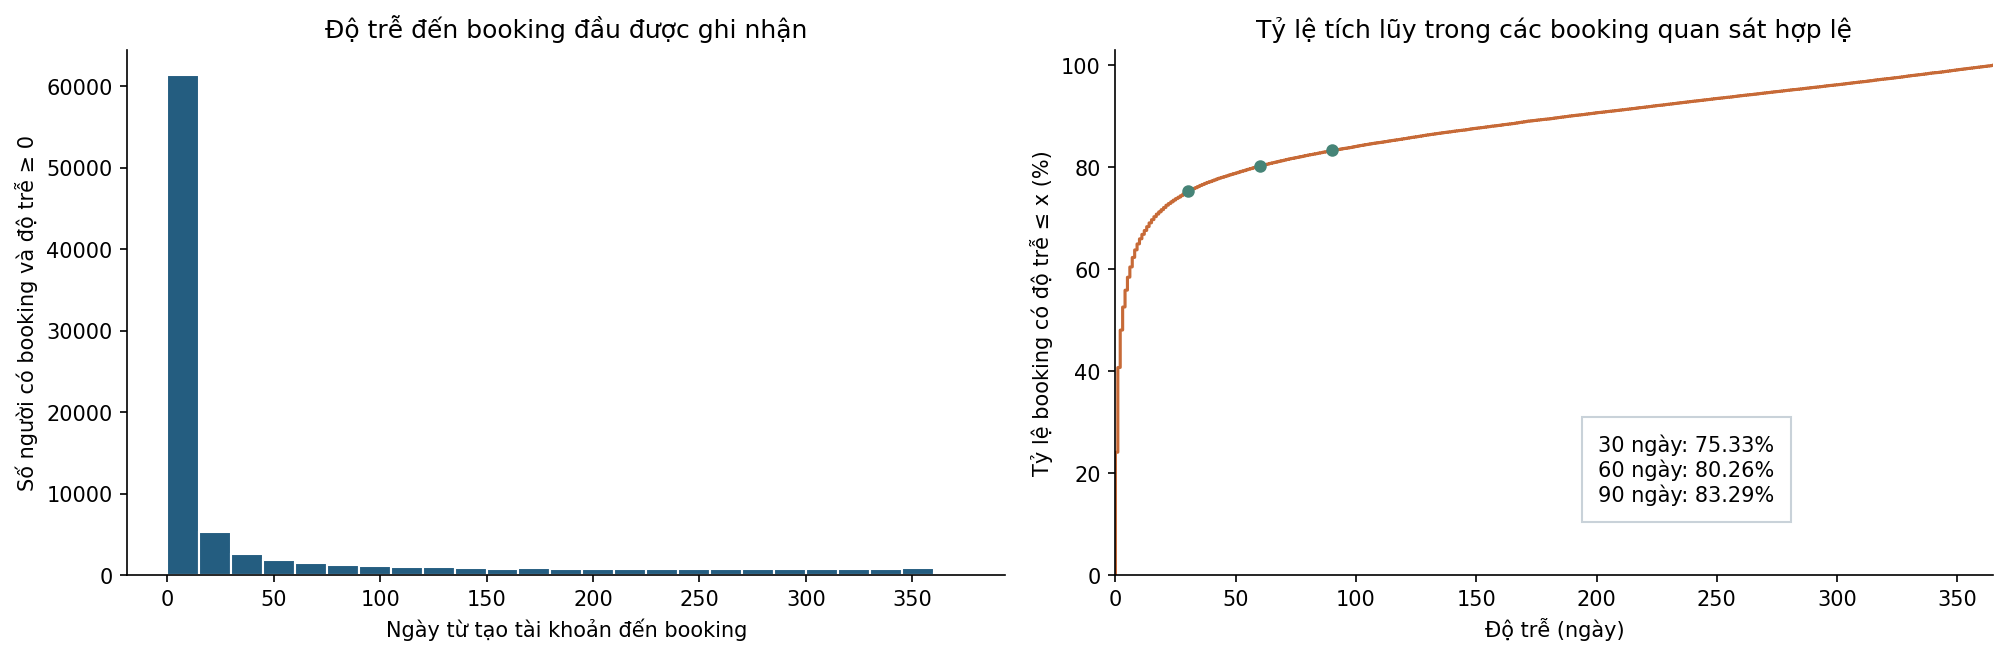

Nhận xét: trong 88,879 booking có độ trễ không âm, 75.33% xảy ra trong 30 ngày, 80.26% trong 60 ngày và 83.29% trong 90 ngày. Đây là phân phối có điều kiện trên người đã book; chưa xác định thời gian theo dõi của NDF. 29 độ trễ âm được báo riêng, không xóa khỏi raw.

### Độ mạnh liên hệ với nhãn trên toàn bộ biến ứng viên

Phạm vi sàng lọc gồm 13 cột ứng viên gốc: 10 biến phân loại, age và hai mốc thời gian. Cờ thiếu tuổi là một góc nhìn EDA bổ sung, không được xuất thành feature. Ngày tạo account/hoạt động đầu được nhóm theo tháng chỉ để mô tả cohort. ID, nhãn và date_first_booking không được dùng để chứng minh tín hiệu đầu vào.

Cramér V = sqrt(chi-square / [n × min(r−1,c−1)]), trong [0,1]; càng lớn là liên hệ biên càng mạnh. Cột effect_2014 tính lại trên cohort 2014 để kiểm tra ảnh hưởng thành phần năm. Không áp một ngưỡng V chung để tuyên bố biến hữu ích cho mô hình. P-value nhỏ khi n lớn chưa đảm bảo hiệu ứng có giá trị; các category hiếm làm kiểm định chi-square xấp xỉ kém hơn.

Tuổi được kiểm định Mann–Whitney hai phía trong cửa sổ tham chiếu 16–100, kèm rank-biserial trong [−1,1]. Dấu dương nghĩa tuổi ở nhóm booked có xu hướng cao hơn NDF; trị tuyệt đối gần 0 là khác biệt nhỏ. Không so trực tiếp trị số rank-biserial với V như cùng một thang đo. Tuổi ngoài dải và NA vẫn được báo riêng.

Đây là bằng chứng **liên hệ thống kê trong mẫu**, thay cho việc bịa ra AUC ở giai đoạn chưa train; chưa chứng minh khả năng dự báo ngoài thời gian hoặc tác động nhân quả. Nguồn phương pháp: [Cramér V của SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.association.html), [Mann–Whitney của SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html).

**Độ mạnh liên hệ toàn kỳ và trong cohort 2014; nêu đủ 14 phép sàng lọc**

,variable,effect_metric,effect_all,effect_2014,n_all,n_2014,groups_all,expected_cells_under_5_pct,p_chi2_or_mwu,q_bh_14_tests
0,gender,Cramér V,0.2073,0.2507,213451,76466,4.0000,0.0000,<1e-300,<1e-300
1,signup_method,Cramér V,0.0359,0.0371,213451,76466,3.0000,0.0000,1.25e-60,1.35e-60
2,signup_flow,Cramér V,0.1470,0.1526,213451,76466,17.0000,17.6471,<1e-300,<1e-300
3,language,Cramér V,0.0425,0.0452,213451,76466,25.0000,12.0000,9.56e-67,1.12e-66
4,affiliate_channel,Cramér V,0.0907,0.1070,213451,76466,8.0000,0.0000,<1e-300,<1e-300
5,affiliate_provider,Cramér V,0.0633,0.0495,213451,76466,18.0000,11.1111,4.02e-171,5.12e-171
6,first_affiliate_tracked,Cramér V,0.0715,0.0870,213451,76466,8.0000,0.0000,3.12e-231,4.37e-231
7,signup_app,Cramér V,0.1095,0.1559,213451,76466,4.0000,0.0000,<1e-300,<1e-300
8,first_device_type,Cramér V,0.1272,0.1758,213451,76466,9.0000,0.0000,<1e-300,<1e-300
9,first_browser,Cramér V,0.1330,0.1833,213451,76466,52.0000,52.8846,<1e-300,<1e-300


### Tỷ lệ booking theo hồ sơ, kênh, thiết bị và missing tuổi

... (21 outputs left out)

**gender × năm signup: tỷ lệ và n**

account_year,gender,2010,2011,2012,2013,2014
0,-unknown-,"53.68% (n=1,509)","54.45% (n=4,617)","35.75% (n=10,993)","28.89% (n=38,799)","26.54% (n=39,770)"
1,FEMALE,61.89% (n=732),"55.51% (n=3,693)","48.52% (n=15,535)","51.05% (n=23,631)","50.84% (n=19,450)"
2,MALE,62.02% (n=545),"53.74% (n=3,439)","48.50% (n=12,846)","51.64% (n=20,436)","50.95% (n=17,174)"
3,OTHER,100.00% (n=2),80.77% (n=26),57.95% (n=88),60.64% (n=94),62.50% (n=72)


**affiliate_channel × năm signup: tỷ lệ và n**

account_year,affiliate_channel,2010,2011,2012,2013,2014
0,api,Không có user,100.00% (n=1),"45.73% (n=1,813)","33.76% (n=3,504)","27.10% (n=2,849)"
1,content,49.47% (n=95),37.50% (n=296),15.97% (n=432),"10.05% (n=1,482)","11.08% (n=1,643)"
2,direct,"61.98% (n=1,310)","56.32% (n=6,578)","47.71% (n=25,114)","43.03% (n=55,522)","38.63% (n=49,203)"
3,other,52.62% (n=650),"52.35% (n=1,593)","39.05% (n=3,201)","32.43% (n=2,661)",36.33% (n=856)
4,remarketing,Không có user,50.00% (n=94),44.96% (n=129),28.18% (n=181),30.64% (n=692)
5,sem-brand,59.46% (n=37),54.95% (n=777),"41.97% (n=2,783)","41.28% (n=9,755)","42.94% (n=12,693)"
6,sem-non-brand,49.11% (n=395),"52.06% (n=1,800)","38.75% (n=4,872)","35.02% (n=6,604)","35.14% (n=5,173)"
7,seo,61.79% (n=301),58.33% (n=636),"45.26% (n=1,118)","43.25% (n=3,251)","44.27% (n=3,357)"


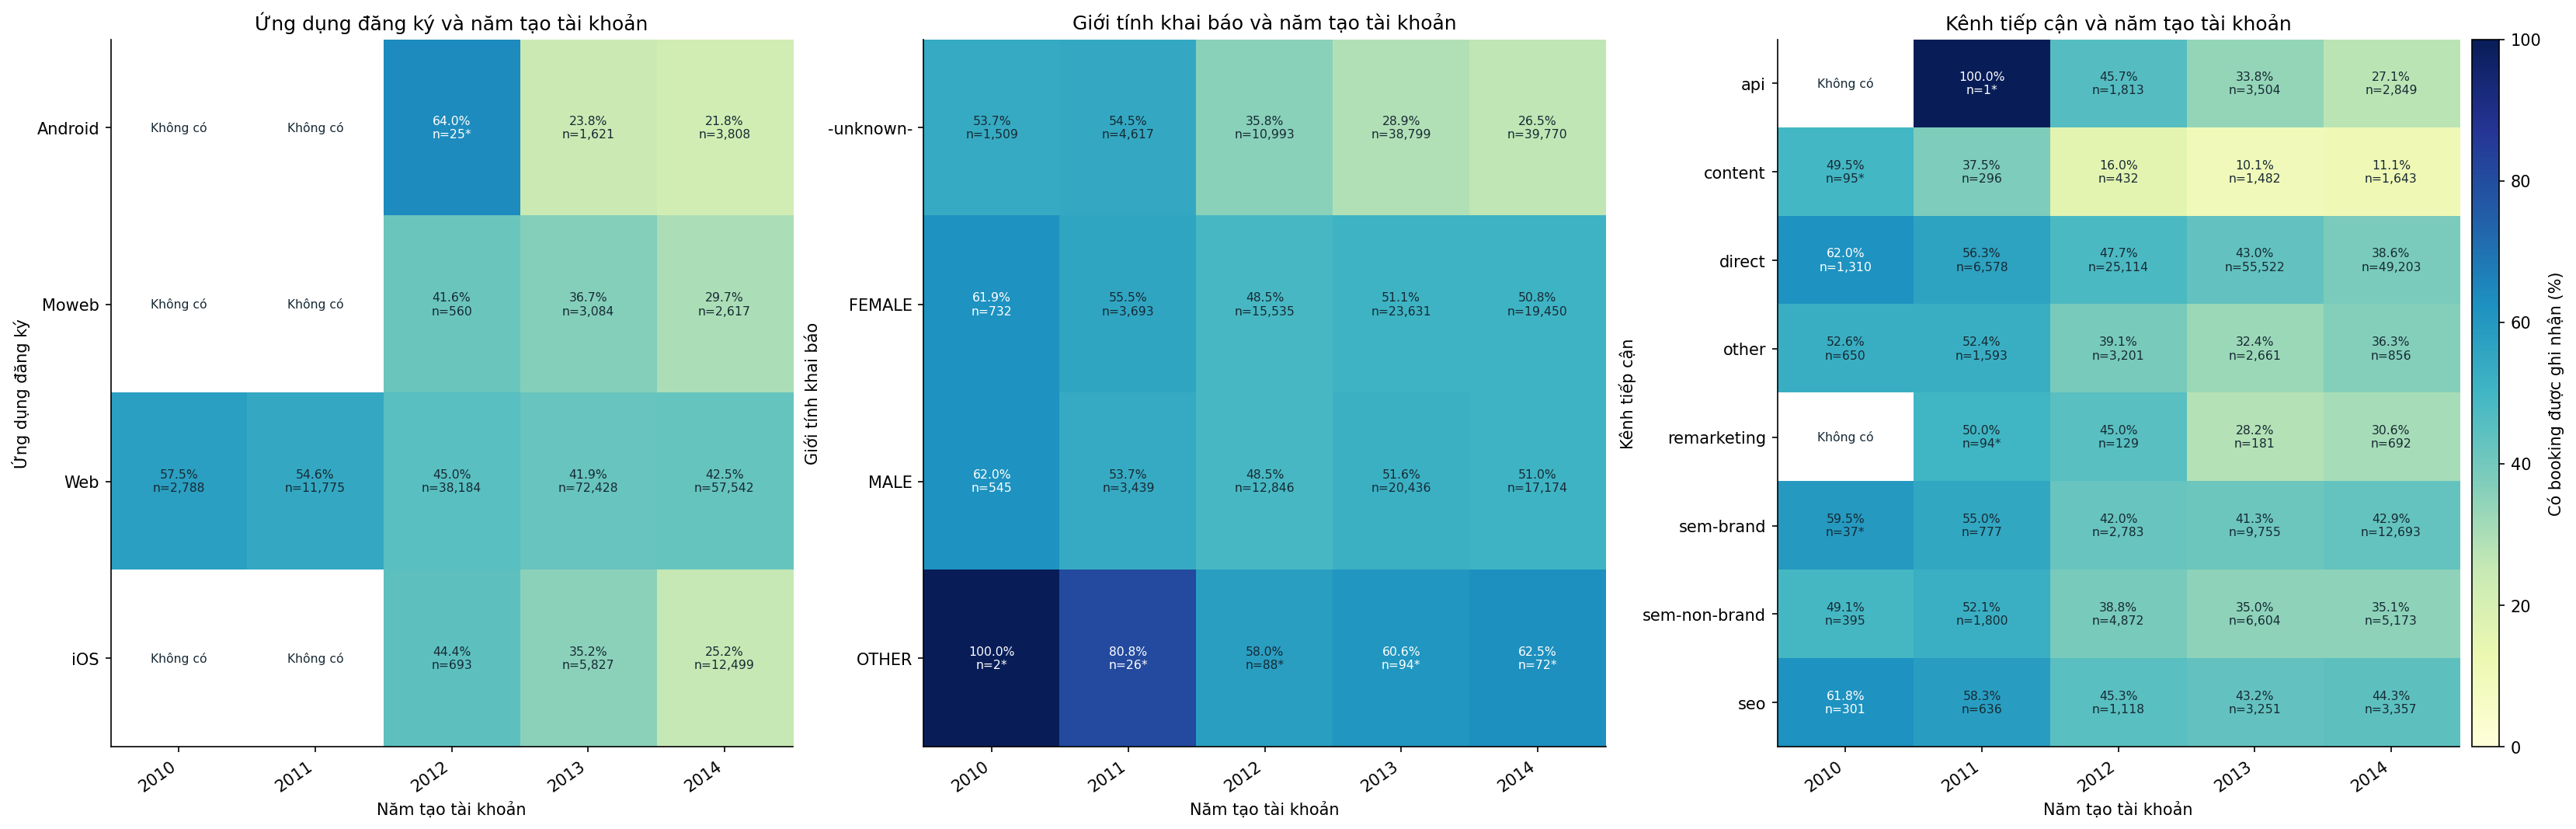

Nhận xét: riêng năm 2014, Web có booking rate 42.53% so với iOS 25.23% và Android 21.85%; chênh lệch app vẫn hiện diện trong cùng năm. FEMALE đạt 50.84% so với gender unknown 26.54%. Nhóm OTHER chỉ có 72 user 2014 nên cần đọc Wilson ở phụ lục. Dấu * là n<100. Phân tầng năm chưa kiểm soát nhiễu theo tháng hoặc biến khác.

### Tương tác liên quan đến nhãn trong cohort 2014

Thay biểu đồ hai trục ngày gần trùng nhau bằng signup_app × affiliate_channel và missing tuổi × gender. Nhóm tuổi/cờ thiếu chỉ tồn tại để tính bảng và hình EDA; chưa xuất dữ liệu đầu vào. Không kiểm định tương tác hàng loạt hoặc tự chọn feature từ hình.

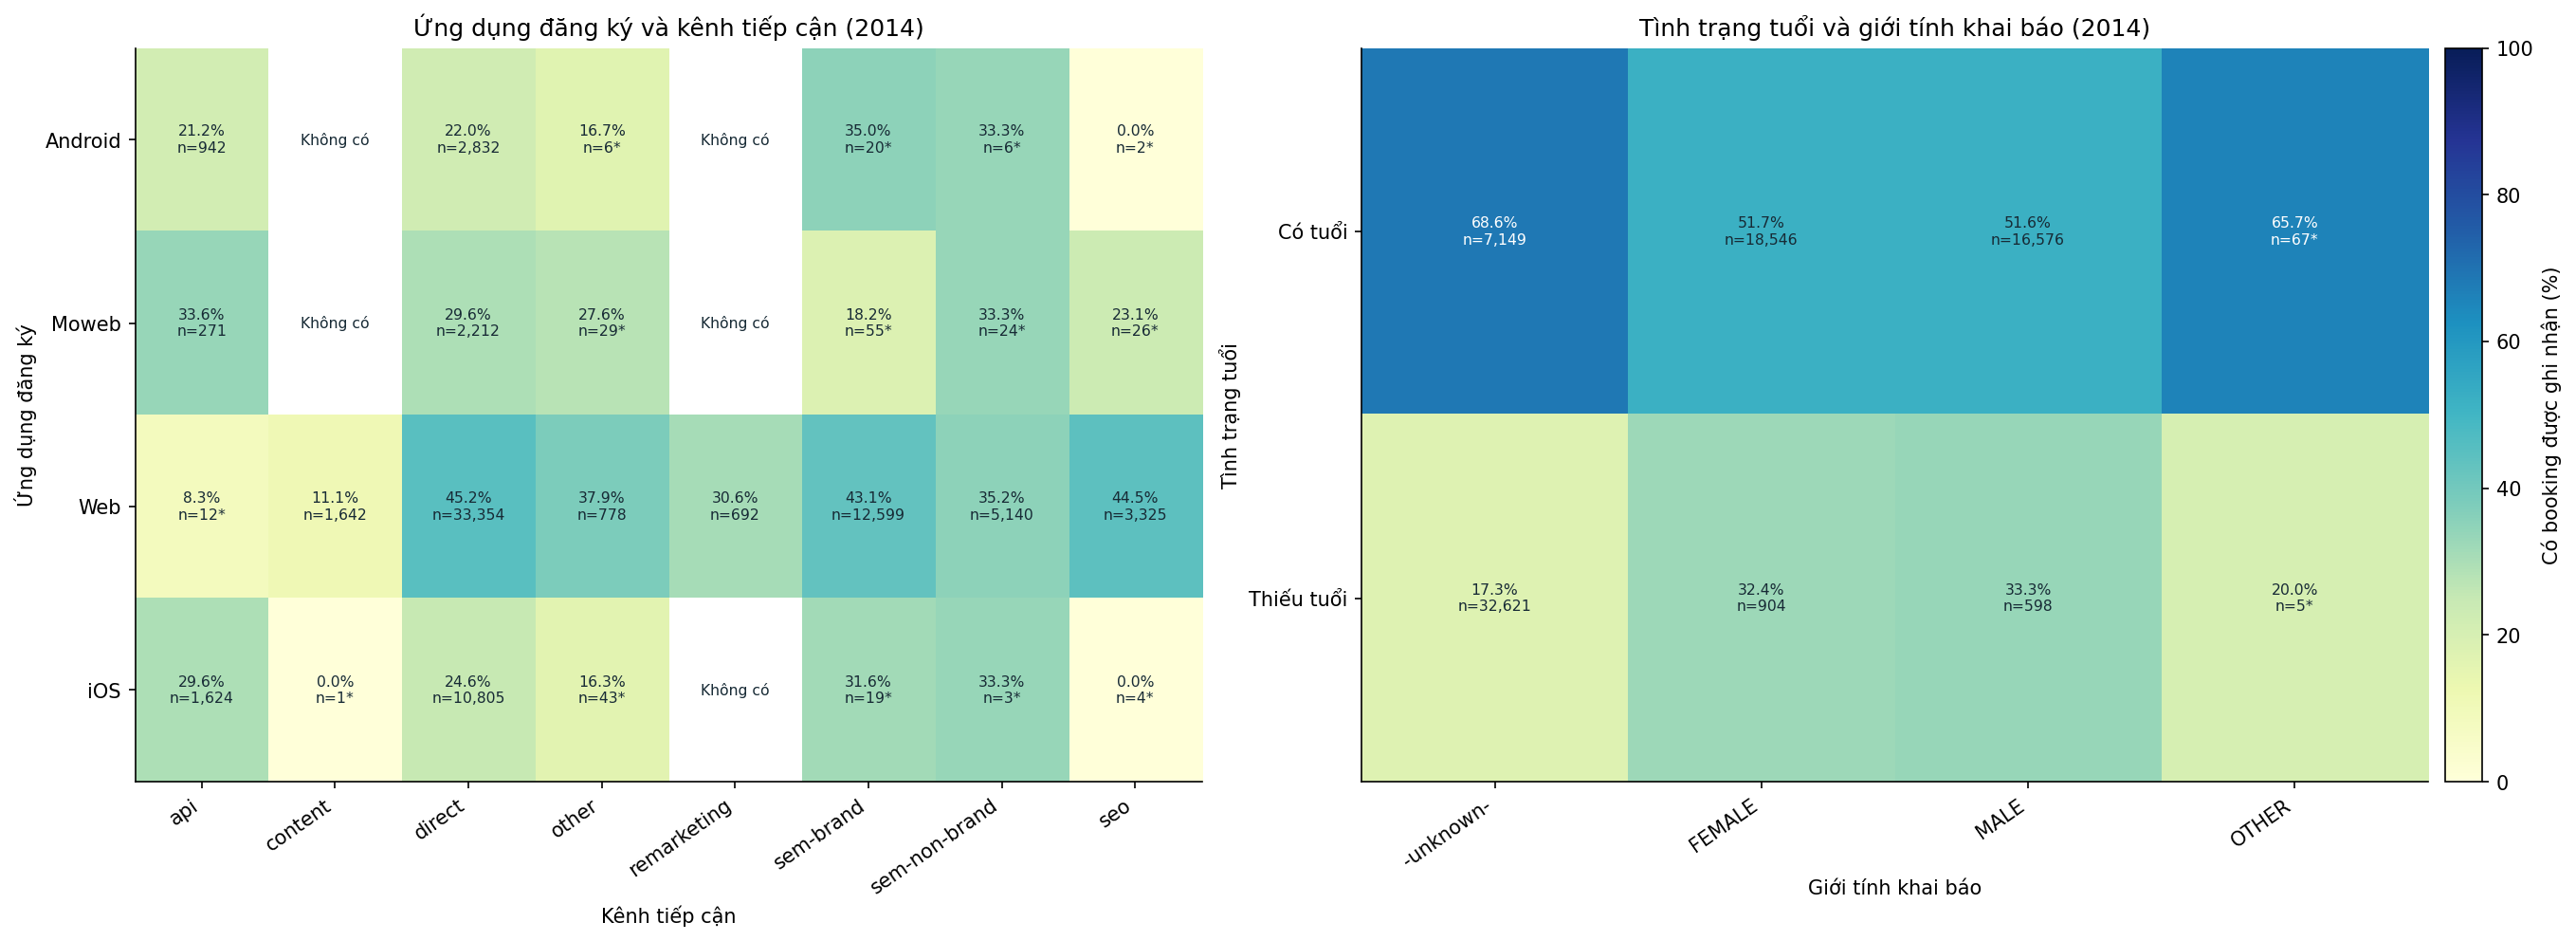

Nhận xét: trong user Web năm 2014, nhóm direct có booking rate 45.18% (n=33,354), nhóm content 11.08% (n=1,642). Trong nhóm FEMALE cùng năm, có tuổi đạt 51.74% so với thiếu tuổi 32.41%. Dấu * là n<100. Liên hệ không chỉ do trộn các năm, nhưng vẫn chưa chứng minh quan hệ nhân quả hoặc mô hình phi tuyến sẽ thắng baseline.

### Sessions: so sánh cùng cohort và rà soát thông tin giao dịch

Đã quét toàn bộ 10,567,737 sự kiện. So sánh phù hợp hơn là **train cohort 2014: 73,815/76,466 (96.53%)** với **test cohort 2014: 99.31%**; chênh 2.78 điểm phần trăm. Tỷ lệ train toàn kỳ 34,58% chủ yếu phản ánh việc cohort 2010–2013 không có log, không phải bằng chứng user ít hoạt động.

**Về độ phủ, nghiên cứu sessions phải giới hạn cohort 2014 (76,466 user train), trong đó 73,815 có log.** Về thời điểm dự đoán, sessions vẫn chưa đủ điều kiện: không có timestamp nên không cắt được trước t0. Giới hạn cohort không tự loại được rò rỉ thời gian.

Bảng có/không có log dưới đây chỉ xét 2014. Bảng số sự kiện giữ cả user không có log với event_n=0 để không nhầm mẫu số. Thời lượng secs_elapsed không phải timestamp và tổng thời lượng không chứng minh thứ tự hành động.

Rà soát tên ứng viên giao dịch/xác minh theo regex **(?:^|_)(?:book[a-z]*|reserv[a-z]*|pay[a-z]*|checkout|receipt|itinerar[a-z]*|confirm[a-z]*|request[a-z]*|billing)(?:_|$)**, trước khi xem liên hệ với nhãn; khớp token phân cách bởi dấu gạch dưới và giữ đầy đủ action_type để đối chiếu. Nhóm confirm/request có thể liên quan xác minh tài khoản hoặc yêu cầu, chưa mặc định là booking hoàn tất. Đếm presence theo user sau khi gộp toàn bộ chunk, tránh một người bị đếm lặp vì nhiều sự kiện. Mẫu số của hai cột pct_booked/pct_ndf là người có sessions trong từng lớp, không phải toàn bộ train.

**Dấu hiệu đáng điều tra:** receipt có 101/102 user mang nhãn booked (99.02%); requested có 6,192/7,090 (87.33%). Tỷ lệ cao phù hợp với rủi ro log chứa bước sát hoặc sau kết quả, chưa chứng minh receipt luôn là hậu booking hoặc requested gây ra booking.

Tên như booking/payment/request là dấu hiệu cần điều tra. Hành động cũng có thể là yêu cầu thất bại, chuẩn bị thanh toán hoặc hoạt động sau booking; xuất hiện ở booked hay NDF chưa chứng minh thứ tự trước/sau kết quả. **Toàn bộ sessions bị loại khỏi phạm vi đầu vào của thiết kế chính tại signup**, cho tới khi có timestamp hoặc chứng cứ về cửa sổ log. Đây là quyết định phạm vi đề xuất, chưa tạo tập feature.

**Độ phủ năm account train**

,account_year,users,users_with_sessions,coverage_pct
0,2010,2788,0,0.0000
1,2011,11775,0,0.0000
2,2012,39462,0,0.0000
3,2013,82960,0,0.0000
4,2014,76466,73815,96.5331


**Booking trong nhóm có/không sessions — chỉ cohort 2014**

,has_sessions,n,positive,rate_pct,ci95_low_pct,ci95_high_pct,n_under_100
0,False,2651,465,17.5406,16.1401,19.0350,False
1,True,73815,28774,38.9812,38.6300,39.3336,False


**Số sự kiện/user theo có log và nhãn — chỉ cohort 2014**

,has_sessions,observed_booking,users,mean_events,median_events,p90_events,p99_events,max_events
0,False,0,2186,0.0000,0.0000,0.0000,0.0000,0
1,False,1,465,0.0000,0.0000,0.0000,0.0000,0
2,True,0,45041,67.8873,33.0000,167.0000,485.6000,2323
3,True,1,28774,86.1975,45.0000,207.0000,592.0000,2644


**Presence tên ứng viên giao dịch/xác minh × nhãn, trong user 2014 có log**

,field,value,users_with_action,booked_users,ndf_users,booking_rate_pct,ci95_low_pct,ci95_high_pct,pct_booked_users_with_action,pct_ndf_users_with_action,n_under_100
7,action,confirm_email,30986,15611,15375,50.3808,49.8241,50.9374,54.2538,34.1356,False
27,action,requested,7090,6192,898,87.3343,86.5398,88.0883,21.5194,1.9937,False
15,action,payment_instruments,3804,1395,2409,36.6719,35.1547,38.2161,4.8481,5.3485,False
25,action,request_new_confirm_email,2619,1754,865,66.9721,65.1472,68.7473,6.0958,1.9205,False
16,action,payment_methods,1901,859,1042,45.1867,42.9615,47.4314,2.9853,2.3134,False
3,action,apply_reservation,1344,889,455,66.1458,63.5731,68.6265,3.0896,1.0102,False
20,action,payout_preferences,933,386,547,41.3719,38.2534,44.5612,1.3415,1.2144,False
29,action,tos_confirm,899,287,612,31.9244,28.9594,35.0431,0.9974,1.3588,False
24,action,recent_reservations,796,365,431,45.8543,42.4210,49.3274,1.2685,0.9569,False
14,action,pay,737,563,174,76.3908,73.1928,79.3151,1.9566,0.3863,False


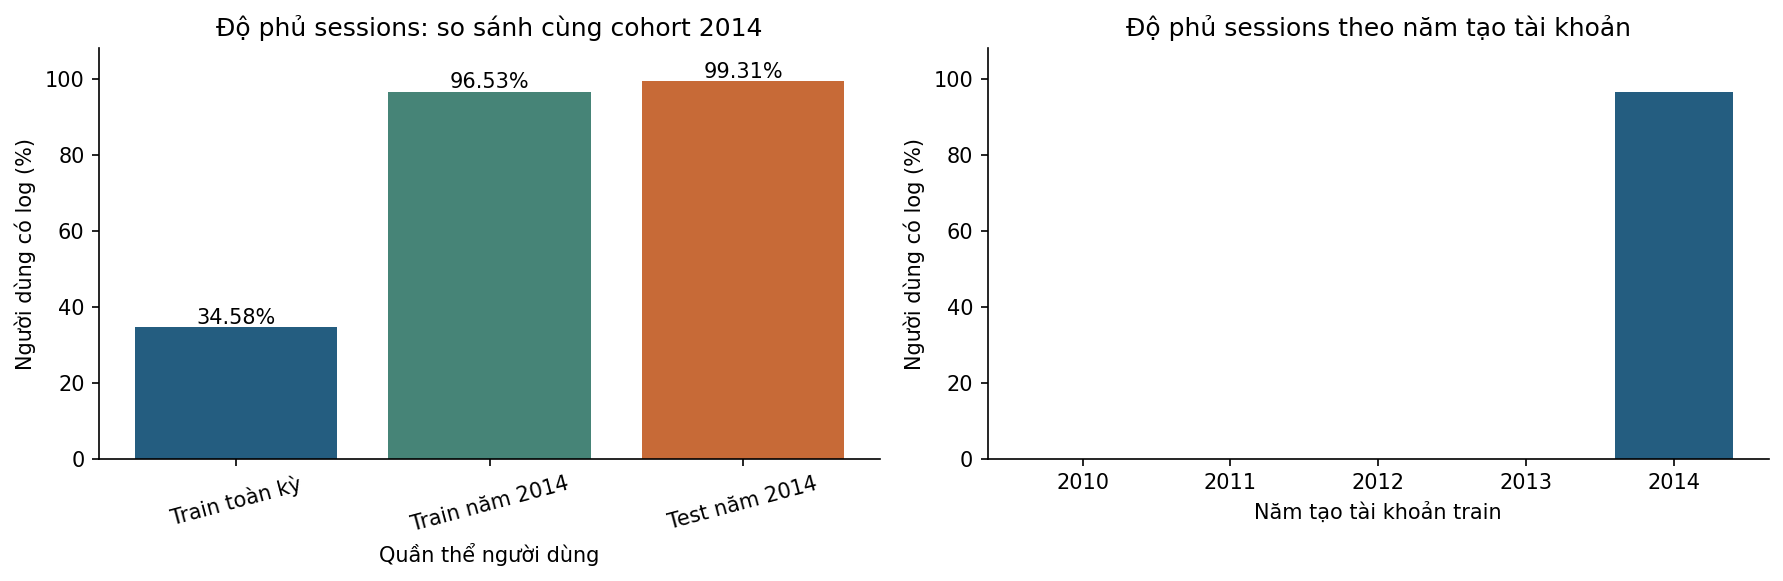

Nhận xét: độ phủ train toàn kỳ 34,58% là hỗn hợp cohort; train 2014 đạt 96.53% so với test 2014 99.31%, chênh 2.78 điểm phần trăm. Không có log ở cohort 2010–2013. Độ phủ cao không chứng minh log được ghi trước thời điểm dự đoán.

### Cohort tháng có bất định và drift train–test

Train có account 2010-01–2014-06; test 2014-07–2014-09 và không có nhãn. Hình giữ từng tháng, thêm Wilson 95% và ranh giới 2014-01 khi bắt đầu có sessions. Tháng ít user có khoảng rộng hơn; đường lên/xuống chưa chứng minh chất lượng khách hoặc mùa vụ.

Total variation trong [0,1] chỉ so sánh phân phối từng biến. Hai cột toàn kỳ và chỉ train 2014 giúp thấy phần thay đổi do thành phần cohort; chưa loại được drift trong năm hoặc drift quan hệ với nhãn. Các bảng khoảng thời gian và drift xuất hiện duy nhất tại đây; phụ lục chỉ giữ số liệu cohort tháng.

**Khoảng thời gian account**

,population,account_min,account_max,users
0,train,2010-01-01,2014-06-30,213451
1,test,2014-07-01,2014-09-30,62096


**Khác biệt category train–test: toàn kỳ và cùng năm 2014**

,column,tv_all_train_vs_test,test_only_categories,train_missing_pct,test_missing_pct,tv_train2014_vs_test
0,first_device_type,0.3121,0,0.0000,0.0000,0.2337
1,first_browser,0.2595,3,0.0000,0.0000,0.1848
2,signup_app,0.2569,0,0.0000,0.0000,0.1534
3,signup_flow,0.2201,1,0.0000,0.0000,0.1372
4,affiliate_channel,0.1574,0,0.0000,0.0000,0.1119
5,gender,0.0959,0,0.0000,0.0000,0.0241
6,affiliate_provider,0.0920,0,0.0000,0.0000,0.0944
7,first_affiliate_tracked,0.0798,0,2.8414,0.0322,0.0824
8,signup_method,0.0419,1,0.0000,0.0000,0.0237
9,language,0.0137,1,0.0000,0.0000,0.0105


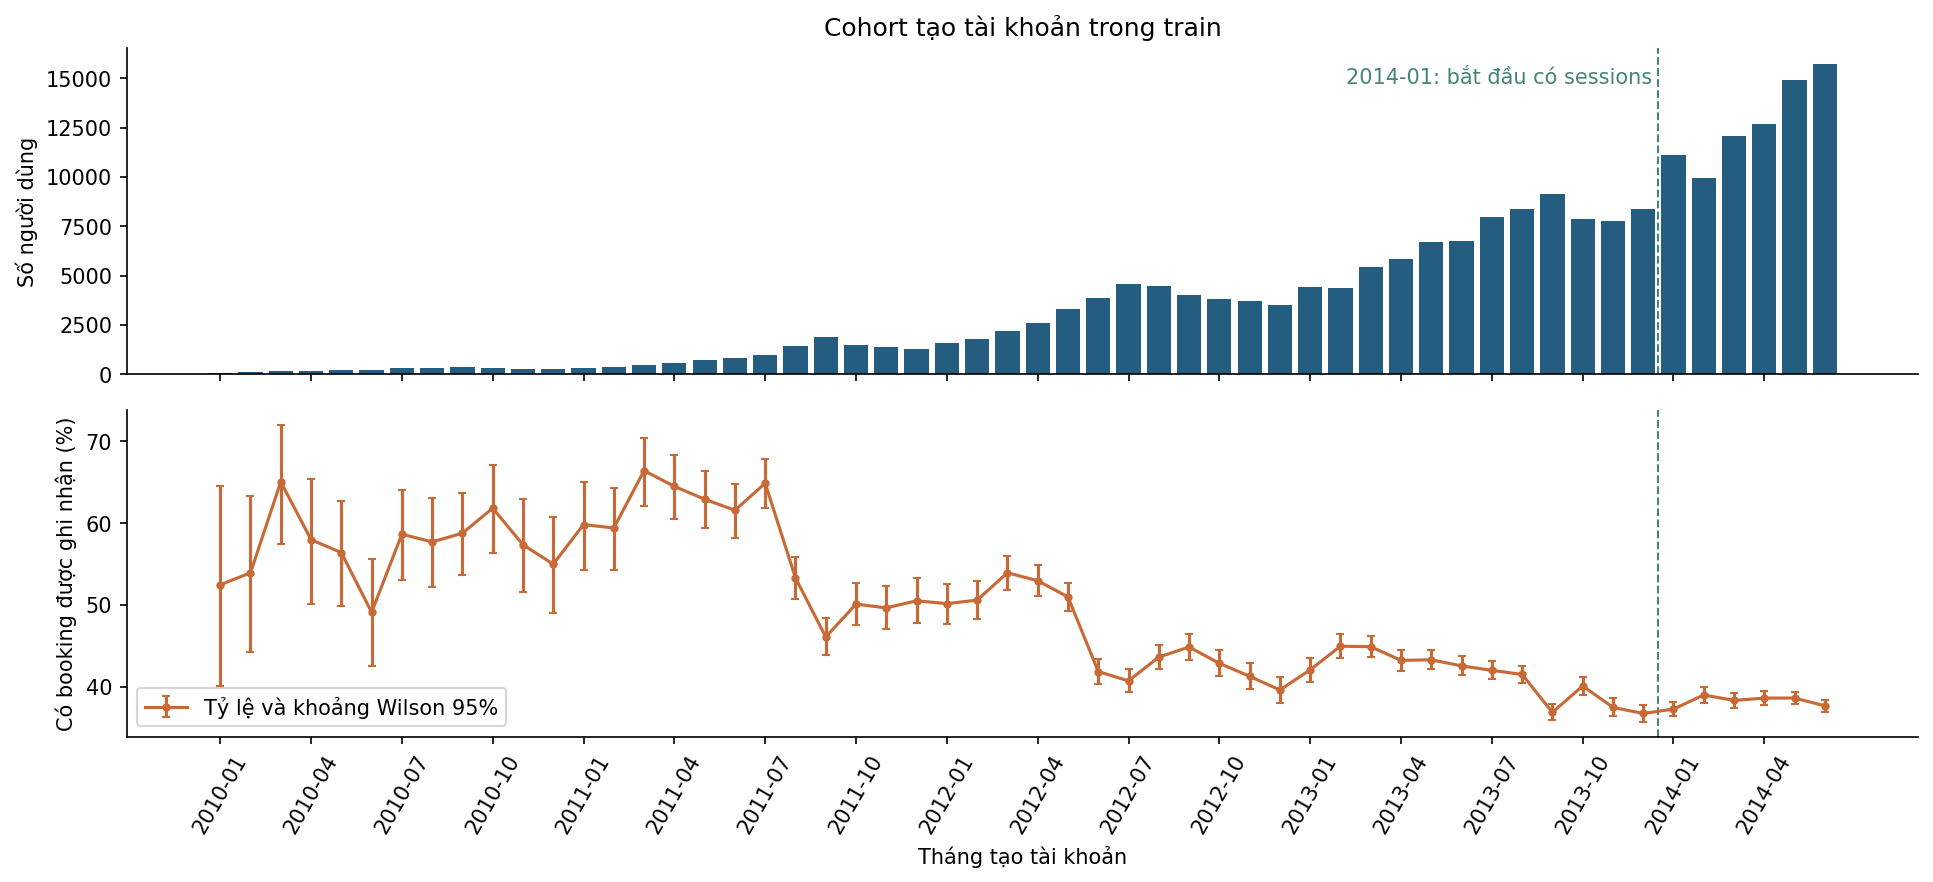

Nhận xét: tháng 2010-01 chỉ có 61 user, booking rate 52.46% với Wilson 95% [40.16%; 64.47%]; vì vậy dao động ở cohort nhỏ cần đọc cùng bất định. Vạch đứt 2014-01 đánh dấu thay đổi độ phủ sessions, không phải bằng chứng về tác động riêng của thời gian đăng ký.

In [7]:
eda.show_section(report, 'multivariate_main')

## 6. Hạn chế, rủi ro và quyền riêng tư

In [8]:
eda.show_section(report, 'risks')

Tách điều đã quan sát khỏi nguyên nhân chưa được chứng minh. Không diễn giải chênh lệch nhóm thành đặc điểm cố hữu của giới tính/tuổi/quốc gia và không thực hiện nhận diện lại cá nhân.

**Rủi ro và giới hạn sử dụng**

,issue,evidence_or_limit
0,Quyền riêng tư,"ID là mã giả danh; age, gender, ngày hoạt động..."
1,Quần thể,Users từ Mỹ trong giai đoạn lịch sử; thời gian...
2,Nhóm nhỏ / bias,PT/AU và các category hiếm có ít quan sát; khá...
3,Rò rỉ,date_first_booking tiết lộ nhãn; log không có ...
4,Đồng ý / quyền sử dụng,CSV không có biểu mẫu đồng ý hay hồ sơ pháp lý...
5,Giới hạn suy luận,"EDA là mô tả, không phải kiểm định tác động ca..."


## 7. Thuật toán và thiết kế đánh giá đề xuất

In [9]:
eda.show_section(report, 'research_design')

### Baseline, mô hình chính và xác suất

Chọn nhị phân first-booking theo nhãn nguồn làm bài toán chính. Binary 41,65%/58,35% không cần mặc định resampling hoặc class weight; lớp điểm đến hiếm không phải lý do cân bằng lại nhãn nhị phân.

CatBoost là ứng viên chính để kiểm tra, không phải kết luận đã thắng baseline. Tín hiệu EDA và tương tác chỉ là cơ sở đặt giả thuyết. Mọi quy tắc xử lý tuổi, NA/category hiếm và mọi thống kê dựa nhãn phải học riêng trong train của mỗi fold. ID và date_first_booking không làm đầu vào; sessions chưa thuộc thiết kế chính.

Nguồn thuật toán: [xử lý category của CatBoost](https://catboost.ai/docs/en/concepts/algorithm-main-stages_cat-to-numberic). Hiệu chỉnh phải tách khỏi dữ liệu fit; [scikit-learn về calibration](https://scikit-learn.org/stable/modules/calibration.html) cũng lưu ý Brier/log loss đánh giá cả calibration lẫn khả năng phân biệt.

**Ứng viên và lý do chọn — chưa thực hiện**

,candidate,reason_from_eda,proposed_controls,status
0,Baseline xác suất hằng,p bằng tỷ lệ booking trong phần train của từng...,Mốc đối chứng log loss/Brier; không dùng tỷ lệ...,Chưa chạy
1,Baseline Logistic Regression + L2,"Quan hệ cộng, dễ đối chiếu với liên hệ biên EDA",One-hot/nhóm hiếm và xử lý tuổi/missing chỉ họ...,Chưa chạy
2,Mô hình chính đề xuất: CatBoost nhị phân,"Nhiều category, missing có cấu trúc và các nhó...",Xử lý category bằng cơ chế của mô hình; numeri...,Chưa chạy
3,Hiệu chỉnh xác suất sigmoid,"Propensity cần xác suất có ý nghĩa, không chỉ ...",Fit trên cohort calibration tách riêng; chỉ dù...,Chưa chạy


### Chia theo thời gian và kiểm soát đánh giá

Thiết kế dưới đây được đặt trước lần huấn luyện đầu tiên. Rolling validation dùng để chọn cấu hình; sau đó refit đến hết 2014-03, calibration trên 2014-04, đánh giá nội bộ cuối trên 2014-05–06. Mỗi user chỉ một dòng và một giai đoạn trong từng fold; các cửa sổ học tích lũy giữa fold là có chủ đích. Test Kaggle 2014-07–09 không có nhãn, chỉ dùng đối chiếu schema/drift.

Bảng chỉ kiểm kê quy mô các cửa sổ đề xuất, chưa tạo tập chia hoặc fit. Việc chia theo signup đánh giá thay đổi cohort, chưa mô phỏng đầy đủ một backtest tại thời điểm lịch: cần chứng minh nhãn train đã được đóng và có sẵn trước mỗi mốc dự đoán. Nếu sau này dùng horizon 90 ngày, phải thêm điều kiện trưởng thành nhãn trước origin; chưa được lấy booking tương lai để giả lập huấn luyện tại quá khứ.

Chọn tham số/early stopping bằng validation; chọn phương pháp calibration bằng dữ liệu phát triển, fit calibrator trên tháng 4. Giữ tập cuối cho một lần đánh giá sau khi khóa thiết kế. Các khoảng bootstrap đề xuất phải lấy mẫu theo user, seed=42; chưa chạy bootstrap.

... (2 outputs left out)

### Tiêu chí chấp nhận đặt trước

Các mức 2%, 10%, 1,20, 2/3 điểm phần trăm và ngân sách top 20% là quy ước nghiên cứu đề xuất, không phải chuẩn phổ quát hoặc cam kết hiệu quả kinh doanh. Khi có chi phí/lợi ích thực tế cần chốt lại trước huấn luyện và ghi phiên bản protocol. Tất cả trạng thái hiện tại là chưa đánh giá.

**Cổng chấp nhận cho giai đoạn mô hình hóa**

,criterion,predeclared_acceptance,interpretation
0,Toàn vẹn và khả dụng,0 ID trùng giữa các tập; 0 biến kết quả hoặc l...,Điều kiện bắt buộc trước fit
1,Xác suất,Log loss giảm ít nhất 2% tương đối so với base...,Đề xuất nghiên cứu; chưa có kết quả
2,Phân biệt,Average Precision cao hơn prevalence của tập đ...,Đánh giá trên phân phối tự nhiên
3,Ưu tiên,"Lift@20% ít nhất 1,20 và cận dưới bootstrap us...","20% là ngân sách nghiên cứu giả định, chưa phả..."
4,Calibration,Sai lệch mean p so với booking rate ≤2 điểm ph...,Báo cả Brier; hai số này chưa đủ đánh giá cali...
5,Độ bền thời gian,Log loss tốt hơn baseline hằng trong từng thán...,Không chọn mô hình chỉ từ một tháng thuận lợi


## 8. Bằng chứng về mức độ phù hợp

In [10]:
eda.show_section(report, 'conclusion_main')

**Kết luận lựa chọn:** Airbnb phù hợp nhất trong ba bộ cho nghiên cứu propensity booking đầu ở cấp user. Có cỡ mẫu và liên hệ mô tả để tiếp tục thiết kế nghiên cứu. Chưa đủ bằng chứng xác nhận một mô hình triển khai tại signup với horizon 90 ngày.

Các điều kiện về t0, ngoại lệ nhãn và thời gian theo dõi là cổng dữ liệu cần giải quyết; không được biến thành giả định ngầm để đánh dấu mọi tiêu chí đều đạt. Chưa làm sạch, thay thế tuổi/NA, mã hóa, tạo feature, tạo tập chia hay huấn luyện mô hình. Các nhóm, cờ và tổng sessions chỉ dùng để tính bảng EDA trong bộ nhớ.

**Bảng kiểm mức độ phù hợp**

,criterion,evidence_in_report,status,remaining_condition
0,Đủ tín hiệu,"10 category được sàng lọc V; gender V=0.207, t...",Đạt ở mức EDA,Chưa chứng minh dự báo ngoài mẫu; không dùng p...
1,Đủ cỡ mẫu,"213,451 users; 88,908 booking; cohort 2014 76,466",Đạt tổng thể,Một số category/ô tương tác ít user; dùng n và CI
2,Nhãn tin cậy,Presence ngày booking khớp 100%; 29 độ trễ âm;...,Cần xác minh,Chưa xác nhận horizon/follow-up của NDF và ngo...
3,Không rò rỉ,date_first_booking và presence tiết lộ nhãn; s...,Chưa đạt với toàn bộ raw,Thiết kế chính loại các nguồn này; cần audit l...
4,Biến khả dụng tại t0,t0 đã chọn: sau tạo account; raw không cung cấ...,Cần xác minh,Xác nhận snapshot từng biến; ngày account khôn...
5,Ổn định theo thời gian,"Booking rate/cohort, độ phủ sessions và TV cat...",Chưa đạt giả định ổn định,"Dùng kiểm định theo thời gian, không coi train..."
6,Khái quát hóa,"User từ Mỹ, giai đoạn lịch sử; test Kaggle khô...",Chưa được chứng minh,"Chưa suy sang Việt Nam, thị trường hiện tại ho..."


## Phụ lục — từ điển và bảng bổ sung

In [11]:
eda.show_section(report, 'appendix')

### Từ điển users và quan hệ giữa các bảng

`id` là khóa users, ghép một–nhiều với `sessions.user_id`. Cần phân tích users trước và sau ghép mà không làm một người dùng bị nhân thành nhiều quan sát học. `countries` có khóa quốc gia; không ghép bằng điểm đến thật để dự đoán chính nhãn đó. `age_gender_bkts` là thống kê tổng hợp theo bucket/quốc gia/giới tính, không phải thêm 420 khách hàng.

**Schema đầy đủ của train users**

,column,pandas_dtype,distinct_nonnull,missing_n,missing_pct,meaning,role_or_caution,role,unit,observed_domain_and_basis
0,id,object,213451,0,0.0000,Định danh người dùng,Khóa ghép sessions.user_id; không phải phép đo,"định danh / khóa nhóm, không phải số liên tục","mã/nhãn phân loại, không có đơn vị vật lý",Khóa/mã; không in giá trị định danh cá nhân tr...
1,date_account_created,object,1634,0,0.0000,Ngày tạo tài khoản,Mốc cohort; không tự xác định horizon nhãn,ứng viên hồ sơ tại signup; cần xác minh snapshot,ngày/giờ theo định dạng nguồn; timezone chưa x...,Toàn bảng: 2010-01-01–2014-06-30
2,timestamp_first_active,int64,213451,0,0.0000,"Lần hoạt động đầu, dạng YYYYMMDDHHMMSS",Có thể trước ngày tạo tài khoản; cần parse the...,ứng viên hồ sơ tại signup; cần xác minh snapshot,ngày/giờ theo định dạng nguồn; timezone chưa x...,"Toàn bảng: [2.00903e+13, 2.01406e+13], 213451 ..."
3,date_first_booking,object,1976,124543,58.3473,Ngày booking đầu được ghi nhận,Kết quả; presence tiết lộ nhãn có booking,kết quả; loại khỏi đầu vào tại signup,ngày/giờ theo định dạng nguồn; timezone chưa x...,Toàn bảng: 2010-01-02–2015-06-29
4,gender,object,4,0,0.0000,Giới tính khai báo,"-unknown- là sentinel, không phải giá trị biết rõ",ứng viên hồ sơ tại signup; cần xác minh snapshot,"mã/nhãn phân loại, không có đơn vị vật lý","Toàn bảng: '-unknown-', 'FEMALE', 'MALE', 'OTHER'"
5,age,float64,127,87990,41.2226,Tuổi khai báo,Thiếu và giá trị ngoài dải tham chiếu; chưa sử...,ứng viên hồ sơ tại signup; cần xác minh snapshot,năm tuổi khai báo,"Toàn bảng: [1, 2014], 127 giá trị phân biệt"
6,signup_method,object,3,0,0.0000,Phương thức đăng ký,Biến phân loại,ứng viên hồ sơ tại signup; cần xác minh snapshot,"mã/nhãn phân loại, không có đơn vị vật lý","Toàn bảng: 'basic', 'facebook', 'google'"
7,signup_flow,int64,17,0,0.0000,Mã luồng/trang đăng ký,Mã phân loại dù pandas đọc số,ứng viên hồ sơ tại signup; cần xác minh snapshot,"mã/nhãn phân loại, không có đơn vị vật lý","Toàn bảng: [0, 25], 17 giá trị phân biệt"
8,language,object,25,0,0.0000,Ngôn ngữ ưu tiên,Biến phân loại,ứng viên hồ sơ tại signup; cần xác minh snapshot,"mã/nhãn phân loại, không có đơn vị vật lý",Toàn bảng: 25 giá trị khác nhau; top category ...
9,affiliate_channel,object,8,0,0.0000,Kênh marketing liên quan,Không tự chứng minh tác động nhân quả của kênh,ứng viên hồ sơ tại signup; cần xác minh snapshot,"mã/nhãn phân loại, không có đơn vị vật lý","Toàn bảng: 'api', 'content', 'direct', 'other'..."


**So sánh schema train và test**

,column,in_train,in_test
0,id,True,True
1,date_account_created,True,True
2,timestamp_first_active,True,True
3,date_first_booking,True,True
4,gender,True,True
5,age,True,True
6,signup_method,True,True
7,signup_flow,True,True
8,language,True,True
9,affiliate_channel,True,True


... (76 outputs left out)

### Độ trễ trong các cohort tháng gần cuối train

So 2014-01 đến 2014-06 để xem khác biệt trong các booking đã quan sát. Không gán thời gian theo dõi cho NDF từ phân phối dương; tỷ lệ trong ba cột horizon có mẫu số valid_observed_bookings.

**Cohort 2014: NDF và mức bao phủ booking quan sát**

,account_month,users,ndf_users,valid_observed_bookings,within30_pct_of_observed,within60_pct_of_observed,within90_pct_of_observed,max_observed_lag_days
0,2014-01,11111,6969,4142,70.7388,76.7986,80.9754,365.0000
1,2014-02,9967,6079,3888,73.8426,78.8837,82.2274,365.0000
2,2014-03,12058,7436,4622,73.9074,79.4894,82.7997,365.0000
3,2014-04,12689,7788,4901,73.7605,79.6368,83.3095,365.0000
4,2014-05,14895,9141,5754,75.0782,80.0487,83.2986,365.0000
5,2014-06,15746,9814,5932,74.8989,80.0910,82.9231,365.0000


## Tái lập và kiểm soát phạm vi

In [12]:
eda.show_section(report, 'reproducibility')

Notebook cần package scripts/ và năm CSV train_users_2.csv, test_users.csv, sessions.csv, countries.csv, age_gender_bkts.csv tại data/raw/AIRBNB/. Chỉ nộp một file notebook thì xem được output lưu sẵn, chưa thể chạy lại độc lập. Ô mở đầu notebook ghi cấu trúc thư mục và cách cài đúng các thư viện EDA; raw không được đính kèm repo.

Từ thư mục gốc chạy: python scripts/build_descriptive_reports.py --dataset AIRBNB. Hoặc mở notebook bằng Jupyter, Restart Kernel và Run All. Script chỉ đọc CSV raw, xuất Markdown, JSON, hình và notebook có output thật; không tạo data/processed, tập feature, tập chia train/test hay mô hình.

Ngày tải **không được lưu**, đã được người cung cấp xác nhận ngày 2026-11-02. Mã phiên bản Kaggle cũng chưa có bằng chứng. Không điền một ngày giả định: snapshot local được định danh bằng SHA-256 từng file và hash danh mục có thứ tự ở metadata. Ngày phân tích theo Asia/Ho_Chi_Minh khác với ngày tải.

Mọi bảng dùng toàn bộ user hoặc toàn bộ sessions có khóa hợp lệ trong phạm vi ghi cạnh bảng. Chỉ mẫu hình thiếu hiển thị tối đa 300 dòng, seed=42. Cramér V dùng chi-square không hiệu chỉnh Yates; p chi-square là xấp xỉ, kèm tỷ lệ ô kỳ vọng dưới 5. Mann–Whitney hai phía dùng xấp xỉ có hiệu chỉnh ties; rank-biserial = 2U/(n_booked × n_NDF) − 1. BH điều chỉnh 14 phép sàng lọc toàn kỳ; không áp dụng ngưỡng p để tự động chọn feature. Wilson 95% giả định user độc lập và không bao gồm sai lệch chọn mẫu/cohort. Không bootstrap, fit, tối ưu tham số hay tính chất lượng mô hình trong lần chạy EDA.

Output được tính lại trong lần phân tích hiện tại; môi trường dưới đây và SHA-256 ba module dựng báo cáo trong metadata nhận diện code đã chạy. Các đề xuất thuật toán, cửa sổ chia tập và ngưỡng chấp nhận chưa được thực thi.

**Môi trường thực thi chính xác**

,component,value
0,Python,3.14.2
1,pandas,2.3.3
2,numpy,2.4.1
3,matplotlib,3.10.8
4,Phương pháp,"Thống kê mô tả, không mô hình"
5,Chunk CSV lớn,250000
6,scipy,1.17.1
7,nbformat,5.10.4
8,IPython,9.9.0
